# Heuristic Graph Pathfinding Agent Search Engine 

**Algorithms :** Dijkstra · A\* (Manhattan, Euclidean, Weighted) · Q-Learning


In [4]:
import os, time, heapq, json, math, random, shutil
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter
from matplotlib.animation import PillowWriter, FuncAnimation
from IPython.display import display, Markdown

OUT = "/kaggle/working/results" if os.path.exists("/kaggle/working") else "results"
shutil.rmtree(OUT, ignore_errors=True)          # start clean: no stale files from older runs
os.makedirs(OUT, exist_ok=True)

SEED = 42
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Output folder:", OUT)

Output folder: /kaggle/working/results


## 1. Mazes

Grid values: `0` = free, `1` = wall. Four generators:

- **random**: each cell is a wall with probability `wall_prob` (regenerated until a path exists).
- **perfect maze**: a recursive-backtracker maze (one single path), plus optional `loop_prob` to knock down some walls so several routes exist.
- **trap**: a long wall with a gap far from the straight line. The goal is directly "behind" the wall, so the heuristic points the wrong way (a hard case for A\*).
- **blocked**: no path exists (to test that the code does not crash).

`dist_map` runs BFS from the goal and gives the **true** shortest distance of every cell. It is used to check optimality.

In [5]:
def neighbors(grid, cell):
    """Free cells next to `cell` (4 directions)."""
    r, c = cell
    n, m = grid.shape
    for dr, dc in MOVES:
        nr, nc = r + dr, c + dc
        if 0 <= nr < n and 0 <= nc < m and grid[nr, nc] == 0:
            yield (nr, nc)

def dist_map(grid, goal):
    """BFS from the goal: TRUE shortest distance from every cell (-1 = unreachable)."""
    dist = np.full(grid.shape, -1, dtype=int)
    dist[goal] = 0
    q = deque([goal])
    while q:
        cur = q.popleft()
        for nb in neighbors(grid, cur):
            if dist[nb] < 0:
                dist[nb] = dist[cur] + 1
                q.append(nb)
    return dist

def make_random_maze(n, wall_prob, seed=SEED):
    start, goal = (0, 0), (n - 1, n - 1)
    while True:
        grid = (np.random.default_rng(seed).random((n, n)) < wall_prob).astype(int)
        grid[start] = 0
        grid[goal] = 0
        if dist_map(grid, goal)[start] >= 0:     # keep only solvable mazes
            return grid, start, goal
        seed += 1

def make_perfect_maze(n, loop_prob=0.0, seed=SEED):
    """Recursive-backtracker maze. n is made odd. loop_prob removes extra walls (creates loops)."""
    n = n if n % 2 == 1 else n + 1
    rng = np.random.default_rng(seed)
    grid = np.ones((n, n), dtype=int)
    grid[0, 0] = 0
    stack = [(0, 0)]
    while stack:
        r, c = stack[-1]
        options = [(r + 2*dr, c + 2*dc, dr, dc) for dr, dc in MOVES
                   if 0 <= r + 2*dr < n and 0 <= c + 2*dc < n and grid[r + 2*dr, c + 2*dc] == 1]
        if options:
            nr, nc, dr, dc = options[int(rng.integers(len(options)))]
            grid[r + dr, c + dc] = 0
            grid[nr, nc] = 0
            stack.append((nr, nc))
        else:
            stack.pop()
    if loop_prob > 0:
        for r in range(n):
            for c in range(n):
                if grid[r, c] == 1 and ((r % 2 == 0) != (c % 2 == 0)) and rng.random() < loop_prob:
                    grid[r, c] = 0
    return grid, (0, 0), (n - 1, n - 1)

def make_trap_maze(n, noise=0.0, seed=SEED):
    """Wall across the middle with a gap on the far right. Goal is straight below the start.
    noise > 0 adds random obstacles elsewhere, so many different trap mazes can be generated."""
    while True:
        if noise > 0:
            grid = (np.random.default_rng(seed).random((n, n)) < noise).astype(int)
        else:
            grid = np.zeros((n, n), dtype=int)
        grid[n // 2, : n - 1] = 1
        grid[n // 2, n - 1] = 0                      # the gap
        grid[0, 0] = 0
        grid[n - 1, 0] = 0
        if dist_map(grid, (n - 1, 0))[0, 0] >= 0:    # keep only solvable mazes
            return grid, (0, 0), (n - 1, 0)
        seed += 1

def make_blocked_maze(n):
    """No path exists."""
    grid = np.zeros((n, n), dtype=int)
    grid[:, n // 2] = 1
    return grid, (0, 0), (n - 1, n - 1)

## 2. Search algorithms (one function, from scratch)

Dijkstra and A\* are the same algorithm with a different priority:

- priority = `g + weight * h(cell)`
- **Dijkstra**: `h = 0`
- **A\* Manhattan**: `h = |dr| + |dc|` (exact lower bound on a 4-direction grid, so the path stays optimal)
- **A\* Euclidean**: straight-line distance (still optimal, but a *weaker* guess, so it expands more)
- **Weighted A\* (w = 2)**: trusts the heuristic twice as much. Faster, but the path may be up to 2× longer than optimal.

Metrics returned: `path`, `expanded` (order in which cells were expanded), `generated` (cells pushed to the queue), `max_frontier` (largest queue size, a memory measure) and `runtime_ms`.

In [6]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def euclidean(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])

def rebuild(parent, goal):
    path, cur = [], goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    return path[::-1]

def search(grid, start, goal, heuristic=None, weight=1.0):
    """Best-first search. heuristic=None -> Dijkstra. Every step costs 1."""
    t0 = time.perf_counter()
    h = heuristic or (lambda a, b: 0)
    g = {start: 0}
    parent = {start: None}
    h0 = weight * h(start, goal)
    heap = [(h0, h0, start)]                      # (f, h, cell): ties -> smaller h first
    closed, expanded = set(), []
    generated, max_frontier = 1, 1

    while heap:
        f, _, cur = heapq.heappop(heap)
        if cur in closed:
            continue
        closed.add(cur)
        expanded.append(cur)                      # one "expanded node"
        if cur == goal:
            break
        gc = g[cur]
        for nb in neighbors(grid, cur):
            ng = gc + 1
            if nb not in g or ng < g[nb]:
                g[nb] = ng
                parent[nb] = cur
                hv = weight * h(nb, goal)
                heapq.heappush(heap, (ng + hv, hv, nb))
                generated += 1
        max_frontier = max(max_frontier, len(heap))

    ms = (time.perf_counter() - t0) * 1000
    path = rebuild(parent, goal) if goal in closed else None
    return dict(path=path, expanded=expanded, generated=generated,
                max_frontier=max_frontier, runtime_ms=ms)

ALGOS = {
    "Dijkstra":          dict(heuristic=None),
    "A* (Manhattan)":    dict(heuristic=manhattan),
    "A* (Euclidean)":    dict(heuristic=euclidean),
    "Weighted A* (w=2)": dict(heuristic=manhattan, weight=2.0),
}

def run(algo, grid, start, goal):
    return search(grid, start, goal, **ALGOS[algo])


## 3. Correctness tests

Before measuring anything, check that the code is **right**:
every returned path must start at the start, end at the goal, move one cell at a time, avoid walls, and have the **true optimal length** (checked against BFS). Weighted A\* must be at most 2× optimal. A maze with no path must return `None`.

In [7]:
def validate_path(grid, path, start, goal):
    assert path[0] == start and path[-1] == goal, "path must go start -> goal"
    for a, b in zip(path, path[1:]):
        assert abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1, "each move must be one cell"
        assert grid[b] == 0, "path crosses a wall"

n_checks = 0
for i in range(150):
    rng = np.random.default_rng(i)
    n = int(rng.integers(8, 31))
    wp = float(rng.uniform(0.05, 0.38))
    grid, s, g = make_random_maze(n, wp, seed=1000 + i)
    opt = int(dist_map(grid, g)[s])
    for name in ALGOS:
        r = run(name, grid, s, g)
        validate_path(grid, r["path"], s, g)
        steps = len(r["path"]) - 1
        if name == "Weighted A* (w=2)":
            assert opt <= steps <= 2 * opt, (name, steps, opt)
        else:
            assert steps == opt, (name, steps, opt)
        n_checks += 1

for i in range(30):                                   # perfect mazes with loops and noisy trap mazes
    n = int(np.random.default_rng(i).integers(10, 41))
    for grid, s, g in [make_perfect_maze(n, 0.05, seed=2000 + i), make_trap_maze(n, 0.10, seed=3000 + i)]:
        opt = int(dist_map(grid, g)[s])
        for name in ALGOS:
            r = run(name, grid, s, g)
            validate_path(grid, r["path"], s, g)
            steps = len(r["path"]) - 1
            assert (opt <= steps <= 2 * opt) if name == "Weighted A* (w=2)" else steps == opt, (name, steps, opt)
            n_checks += 1

bg, bs, bgl = make_blocked_maze(10)
for name in ALGOS:
    assert run(name, bg, bs, bgl)["path"] is None
print(f"All {n_checks} path checks passed. Blocked maze returns None for every algorithm.")

All 840 path checks passed. Blocked maze returns None for every algorithm.


## 4. Benchmark on many mazes

| Maze type | Sizes | Setting | Mazes per setting |
|---|---|---|:-:|
| random obstacles | 20, 50, 100 | wall probability 10 %, 20 %, 30 %, 35 % | 10 |
| perfect maze | 21, 51, 101 | loop probability 0 %, 5 % | 10 |
| trap | 20, 50, 100 | clean trap (1 maze) + trap with 10 % extra random obstacles | 1 + 10 |

Every random / perfect maze uses its **own independent seed** (derived from size, setting and maze number), so mazes are independent samples and different densities are not nested copies of each other.

Runtime is the **median of 5 runs** (a single run is noisy). Metrics per run:

- **steps**: moves in the final path
- **optimality**: steps ÷ true shortest steps (1.0 = optimal)
- **expanded**: nodes taken from the queue, and **density** = expanded ÷ free cells
- **generated** and **max_frontier**: queue work and memory

In [8]:
N_MAZES, REPEATS = 10, 5

def instances():
    for n in [20, 50, 100]:
        for wp in [0.10, 0.20, 0.30, 0.35]:
            for i in range(N_MAZES):
                yield "random", wp, i, make_random_maze(n, wp, seed=SEED + 1000 * i + 17 * n + int(round(wp * 100)))
    for n in [21, 51, 101]:
        for lp in [0.0, 0.05]:
            for i in range(N_MAZES):
                yield "perfect maze", lp, i, make_perfect_maze(n, lp, seed=SEED + 1000 * i + n + int(round(lp * 100)))
    for n in [20, 50, 100]:
        yield "trap", 0.0, 0, make_trap_maze(n)                              # clean trap
        for i in range(N_MAZES):                                             # trap + 10% random obstacles
            yield "trap", 0.10, i, make_trap_maze(n, 0.10, seed=SEED + 1000 * i + n)

def benchmark_one(grid, start, goal, algo, repeats=REPEATS):
    runs = [run(algo, grid, start, goal) for _ in range(repeats)]
    r = runs[0]
    r["runtime_ms"] = float(np.median([x["runtime_ms"] for x in runs]))
    return r

rows = []
t0 = time.time()
for kind, param, i, (grid, start, goal) in instances():
    opt = int(dist_map(grid, goal)[start])
    free = int((grid == 0).sum())
    for algo in ALGOS:
        r = benchmark_one(grid, start, goal, algo)
        steps = len(r["path"]) - 1
        rows.append(dict(kind=kind, n=grid.shape[0], param=param, maze=i, algo=algo,
                         steps=steps, optimality=steps / opt, runtime_ms=r["runtime_ms"],
                         expanded=len(r["expanded"]), generated=r["generated"],
                         max_frontier=r["max_frontier"], density=len(r["expanded"]) / free))
bench = pd.DataFrame(rows)
bench.to_csv(f"{OUT}/metrics_planners.csv", index=False)
print(f"{len(bench)} runs on {len(bench) // len(ALGOS)} mazes in {time.time() - t0:.0f} s")
bench.head()

852 runs on 213 mazes in 34 s


,kind,n,param,maze,algo,steps,optimality,runtime_ms,expanded,generated,max_frontier,density
0,random,20,0.1,0,Dijkstra,38,1.0,1.287722,370,370,19,1.000000
1,random,20,0.1,0,A* (Manhattan),38,1.0,0.182171,39,72,34,0.105405
2,random,20,0.1,0,A* (Euclidean),38,1.0,1.528431,335,369,35,0.905405
3,random,20,0.1,0,Weighted A* (w=2),38,1.0,0.154434,39,72,34,0.105405
4,random,20,0.1,1,Dijkstra,38,1.0,1.180856,347,349,20,0.991429


## 5. Results

**Table 1** averages every metric per maze type and algorithm.
**Table 2** shows how many fewer nodes each method expands compared with Dijkstra, **on the same maze** (mean ± std over all mazes).

In [9]:
summary = (bench.groupby(["kind", "algo"])[["steps", "optimality", "runtime_ms", "expanded", "density", "max_frontier"]]
           .mean().round(3))
print("Table 1: mean metrics")
display(summary)

base = bench[bench.algo == "Dijkstra"].set_index(["kind", "n", "param", "maze"])["expanded"].rename("dij_expanded")
bench_red = bench.join(base, on=["kind", "n", "param", "maze"])
bench_red["reduction_pct"] = 100 * (1 - bench_red["expanded"] / bench_red["dij_expanded"])
red = (bench_red[bench_red.algo != "Dijkstra"].groupby(["kind", "algo"])["reduction_pct"]
       .agg(["mean", "std"]).round(1))
print("Table 2: % fewer expanded nodes than Dijkstra")
display(red)
summary.to_csv(f"{OUT}/summary_planners.csv")

Table 1: mean metrics


steps  optimality  runtime_ms  expanded  \
kind         algo                                                           
perfect maze A* (Euclidean)     458.733       1.000       5.344  1516.533   
             A* (Manhattan)     458.733       1.000       4.978  1417.233   
             Dijkstra           458.733       1.000       5.913  1722.517   
             Weighted A* (w=2)  460.333       1.008       3.458   987.567   
random       A* (Euclidean)     114.050       1.000      10.563  2710.225   
             A* (Manhattan)     114.050       1.000       2.346   535.650   
             Dijkstra           114.050       1.000      12.288  3192.400   
             Weighted A* (w=2)  124.300       1.082       0.782   193.675   
trap         A* (Euclidean)     167.000       1.000      14.664  3740.333   
             A* (Manhattan)     167.000       1.000       7.975  2026.970   
             Dijkstra           167.000       1.000      14.923  3850.879   
             Weighted A* (w=2)  169.606       1.013       7.276  1857.061   

                                density  max_frontier  
kind         algo                                      
perfect maze A* (Euclidean)       0.627        14.400  
             A* (Manhattan)       0.589        15.700  
             Dijkstra             0.715        13.483  
             Weighted A* (w=2)    0.465        16.967  
random       A* (Euclidean)       0.779        86.850  
             A* (Manhattan)       0.196       221.383  
             Dijkstra             0.956        51.092  
             Weighted A* (w=2)    0.106       110.825  
trap         A* (Euclidean)       0.946        76.030  
             A* (Manhattan)       0.548       144.697  
             Dijkstra             0.999        30.758  
             Weighted A* (w=2)    0.509       127.455

Table 2: % fewer expanded nodes than Dijkstra


mean   std
kind         algo                         
perfect maze A* (Euclidean)     11.8  10.1
             A* (Manhattan)     16.5  14.4
             Weighted A* (w=2)  31.4  25.3
random       A* (Euclidean)     18.9  12.2
             A* (Manhattan)     78.8  16.2
             Weighted A* (w=2)  88.5   9.0
trap         A* (Euclidean)      5.3   3.8
             A* (Manhattan)     45.2   3.0
             Weighted A* (w=2)  49.1   3.6

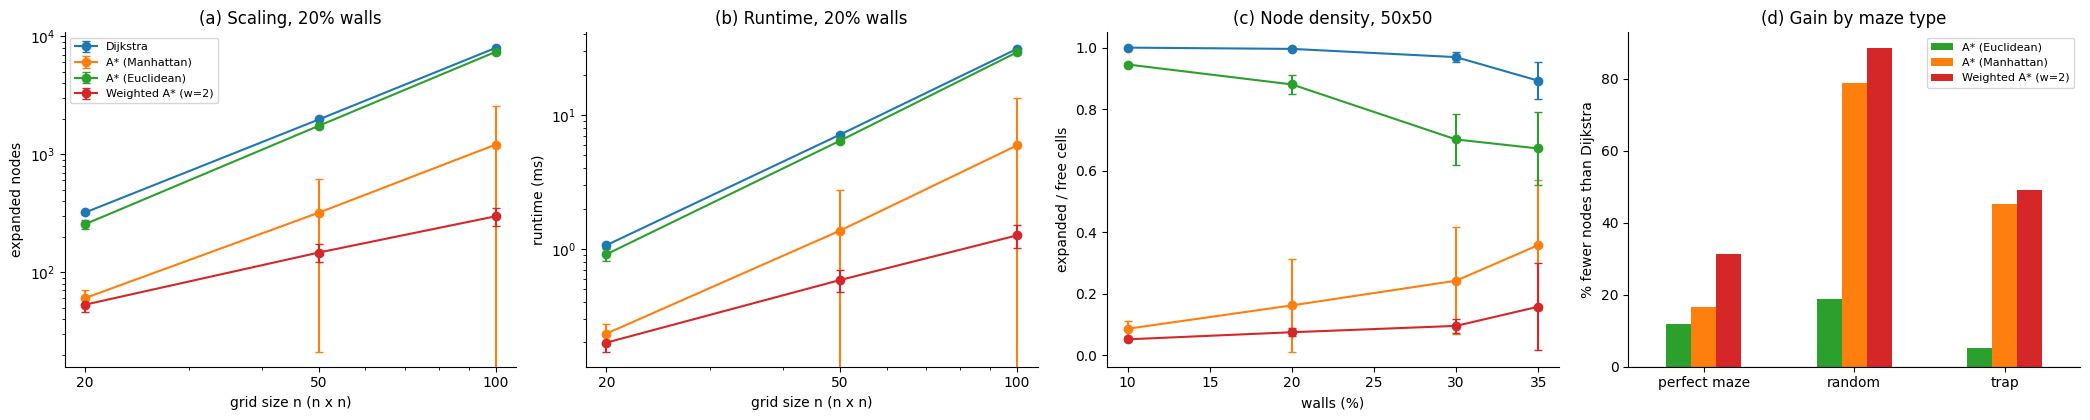

In [10]:
COLORS = dict(zip(ALGOS, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
sel = bench[(bench.kind == "random") & (bench.param == 0.20)]

for algo in ALGOS:                                    # (a) scaling: expanded nodes vs grid size
    d = sel[sel.algo == algo].groupby("n")["expanded"].agg(["mean", "std"])
    ax[0].errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=algo, color=COLORS[algo])
ax[0].set(xscale="log", yscale="log", xlabel="grid size n (n x n)", ylabel="expanded nodes",
          title="(a) Scaling, 20% walls")
ax[0].set_xticks([20, 50, 100]); ax[0].set_xticklabels([20, 50, 100]); ax[0].legend(fontsize=8)

for algo in ALGOS:                                    # (b) runtime vs size
    d = sel[sel.algo == algo].groupby("n")["runtime_ms"].agg(["mean", "std"])
    ax[1].errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=algo, color=COLORS[algo])
ax[1].set(xscale="log", yscale="log", xlabel="grid size n (n x n)", ylabel="runtime (ms)",
          title="(b) Runtime, 20% walls")
ax[1].set_xticks([20, 50, 100]); ax[1].set_xticklabels([20, 50, 100])
for a_ in ax[:2]:
    a_.xaxis.set_minor_formatter(NullFormatter())

sel2 = bench[(bench.kind == "random") & (bench.n == 50)]
for algo in ALGOS:                                    # (c) effect of obstacle density
    d = sel2[sel2.algo == algo].groupby("param")["density"].agg(["mean", "std"])
    ax[2].errorbar(d.index * 100, d["mean"], yerr=d["std"], marker="o", capsize=3, label=algo, color=COLORS[algo])
ax[2].set(xlabel="walls (%)", ylabel="expanded / free cells", title="(c) Node density, 50x50")

pv = red["mean"].unstack("algo")                      # (d) reduction by maze type
pv.plot.bar(ax=ax[3], rot=0, color=[COLORS[a] for a in pv.columns])
ax[3].set(xlabel="", ylabel="% fewer nodes than Dijkstra", title="(d) Gain by maze type")
ax[3].axhline(0, color="k", lw=0.8); ax[3].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT}/planner_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Visualisation: what the search really does

In the pictures: **blue** = expanded cells (light = early, dark = late), **red** = final path, **green** = start, **gold** = goal, **black** = wall.
Dijkstra spreads like a circle in every direction. A\* with a good heuristic pushes toward the goal. In the *trap* maze the heuristic points straight into the wall, so A\* must first fill the pocket in front of it and its advantage shrinks a lot (compare the numbers in Table 2).

Search logs (order of expanded cells + path) are also saved to `search_logs.json`.

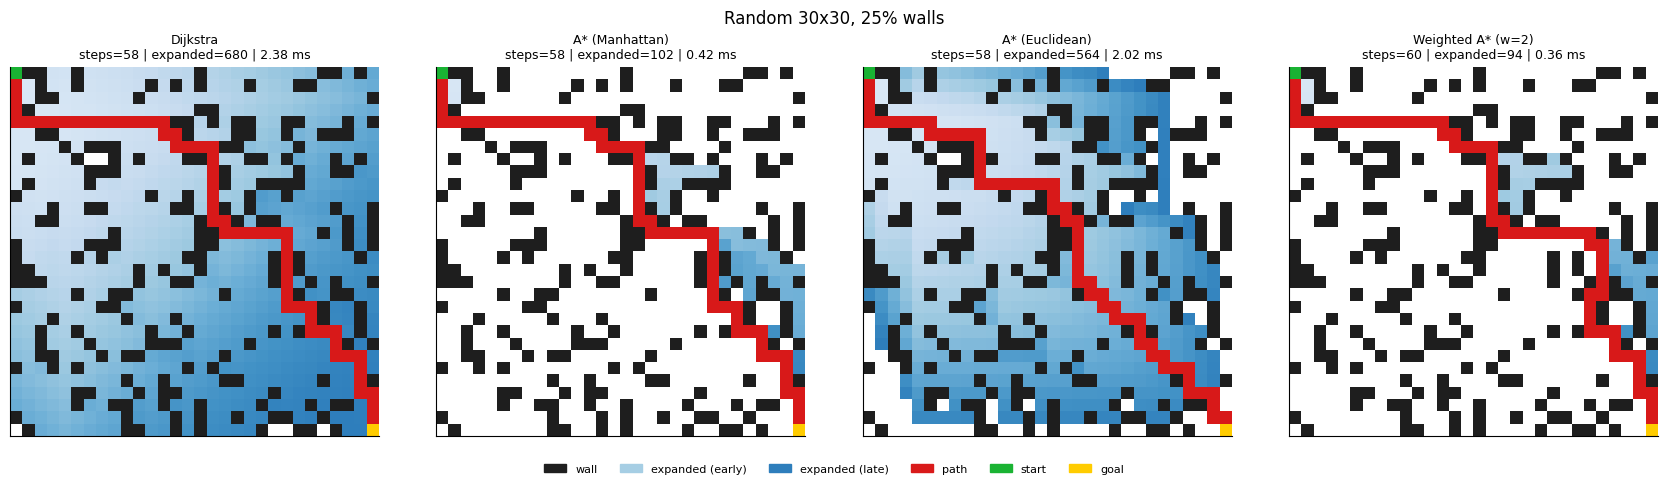

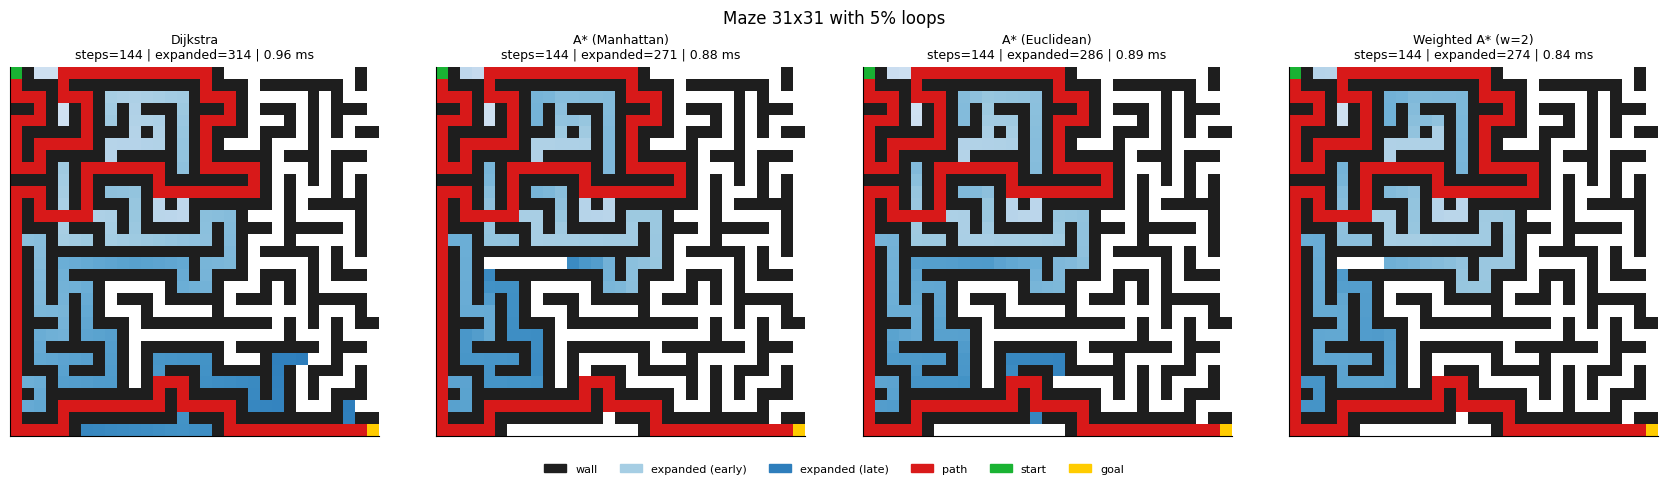

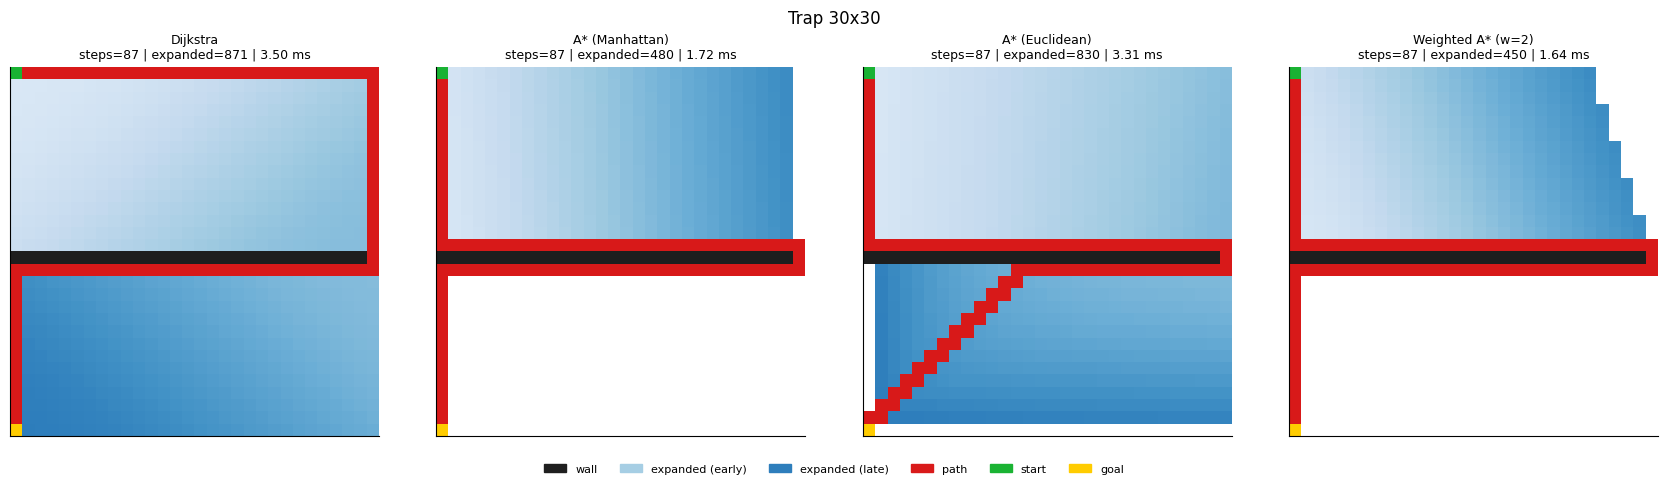

Saved search_logs.json with 12 runs


In [11]:
def draw(grid, start, goal, path, explored, title, ax, total=None):
    rgb = np.ones(grid.shape + (3,))
    rgb[grid == 1] = (0.12, 0.12, 0.12)
    if explored:
        k = max((total or len(explored)) - 1, 1)
        for i, cell in enumerate(explored):
            rgb[cell] = plt.cm.Blues(0.15 + 0.55 * i / k)[:3]    # darker = expanded later
    if path:
        for cell in path:
            rgb[cell] = (0.85, 0.1, 0.1)
    rgb[start] = (0.1, 0.7, 0.2)
    rgb[goal] = (1.0, 0.8, 0.0)
    ax.imshow(rgb, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

LEGEND = [Patch(color=(0.12, 0.12, 0.12), label="wall"), Patch(color=plt.cm.Blues(0.35), label="expanded (early)"),
          Patch(color=plt.cm.Blues(0.7), label="expanded (late)"), Patch(color=(0.85, 0.1, 0.1), label="path"),
          Patch(color=(0.1, 0.7, 0.2), label="start"), Patch(color=(1.0, 0.8, 0.0), label="goal")]

SHOWCASE = {
    "Random 30x30, 25% walls":   make_random_maze(30, 0.25, seed=SEED),
    "Maze 31x31 with 5% loops":  make_perfect_maze(31, 0.05, seed=SEED),
    "Trap 30x30":                make_trap_maze(30),
}

logs = []
for mname, (grid, start, goal) in SHOWCASE.items():
    fig, axes = plt.subplots(1, len(ALGOS), figsize=(4.3 * len(ALGOS), 4.8))
    for ax, algo in zip(axes, ALGOS):
        r = benchmark_one(grid, start, goal, algo)
        steps = len(r["path"]) - 1
        draw(grid, start, goal, r["path"], r["expanded"],
             f"{algo}\nsteps={steps} | expanded={len(r['expanded'])} | {r['runtime_ms']:.2f} ms", ax)
        logs.append(dict(maze=mname, algo=algo, steps=steps, runtime_ms=round(r["runtime_ms"], 3),
                         expanded=len(r["expanded"]), generated=r["generated"],
                         expanded_order=[list(c) for c in r["expanded"]], path=[list(c) for c in r["path"]]))
    fig.suptitle(mname, fontsize=12)
    fig.legend(handles=LEGEND, loc="lower center", ncol=6, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.06, 1, 0.96))
    plt.savefig(f"{OUT}/search_{mname.split(',')[0].replace(' ', '_')}.png", dpi=120, bbox_inches="tight")
    plt.show()

with open(f"{OUT}/search_logs.json", "w") as f:
    json.dump(logs, f)
print("Saved search_logs.json with", len(logs), "runs")

In [12]:
def animate_search(maze, algos, fname, n_frames=40, hold=8):
    """Side-by-side animation: both algorithms after the SAME number of expanded nodes."""
    grid, start, goal = maze
    res = {a: run(a, grid, start, goal) for a in algos}
    longest = max(len(r["expanded"]) for r in res.values())
    fig, axes = plt.subplots(1, len(algos), figsize=(4.6 * len(algos), 4.9))

    def update(f):
        k = min(longest, int(longest * (f + 1) / n_frames))
        for ax, (a, r) in zip(axes, res.items()):
            ax.clear()
            total = len(r["expanded"])
            draw(grid, start, goal, r["path"] if k >= total else None, r["expanded"][:k],
                 f"{a}\nexpanded {min(k, total)} / {total}", ax, total=total)

    FuncAnimation(fig, update, frames=n_frames + hold).save(fname, writer=PillowWriter(fps=8))
    plt.close(fig)

animate_search(SHOWCASE["Random 30x30, 25% walls"], ["Dijkstra", "A* (Manhattan)"], f"{OUT}/anim_random.gif")
animate_search(SHOWCASE["Trap 30x30"], ["Dijkstra", "A* (Manhattan)"], f"{OUT}/anim_trap.gif")
print("Saved GIFs: anim_random.gif, anim_trap.gif")

Saved GIFs: anim_random.gif, anim_trap.gif


## 7. Q-Learning (reinforcement learning)

**Idea in one sentence:** the agent has no map. It tries moves, gets rewards, and slowly fills a table `Q[cell, action]` that says "how good is this move from this cell".

| RL term | In this project |
|---|---|
| State | the cell the agent stands on |
| Action | up, down, left, right |
| Reward | `-1` per step, `-5` for hitting a wall (agent stays), `+100` for reaching the goal |
| Episode | one attempt from the start until the goal (or a step limit) |
| Policy | in each cell take the action with the highest Q (the arrows in the pictures) |

**Update rule:** `Q[s,a] += alpha * (reward + gamma * max(Q[s']) - Q[s,a])`

- `alpha` = learning rate (how far to move toward the new estimate)
- `gamma` = discount (how much the future matters)
- `epsilon` = chance of a random move (**explore**) instead of the best known move (**exploit**). It decays from 1.0 to 0.05.

**What is faster than the first version:** the result of every (cell, action) is precomputed once (`build_env`), so each step is just list look-ups.
**New metrics:** `converged_at` = the episode after which the greedy path is *always* optimal; `visits_to_converge` = how many cell visits the agent needed until then (the fair comparison with A\*'s expanded nodes); `optimal` = did it find the true shortest path.

In [13]:
R_DEFAULT = (-1, -5, 100)        # (step, wall, goal)

def build_env(grid, goal, rewards=R_DEFAULT):
    """Precompute next-state and reward for every (state, action). State id = row * n_cols + col."""
    r_step, r_wall, r_goal = rewards
    n, m = grid.shape
    nxt = [[0] * 4 for _ in range(n * m)]
    rew = [[0.0] * 4 for _ in range(n * m)]
    for r in range(n):
        for c in range(m):
            s = r * m + c
            for a, (dr, dc) in enumerate(MOVES):
                nr, nc = r + dr, c + dc
                if not (0 <= nr < n and 0 <= nc < m) or grid[nr, nc] == 1:
                    nxt[s][a], rew[s][a] = s, r_wall                 # bump into wall: stay
                else:
                    nxt[s][a] = nr * m + nc
                    rew[s][a] = r_goal if (nr, nc) == goal else r_step
    return nxt, rew

def extract_path(Q, nxt, start, goal, m):
    """Follow argmax(Q) from `start`. Returns list of cells, or None if stuck or looping."""
    s, g = start[0] * m + start[1], goal[0] * m + goal[1]
    path, seen = [s], {s}
    while s != g:
        q = Q[s]
        a = q.index(max(q))
        ns = nxt[s][a]
        if ns == s or ns in seen:
            return None
        path.append(ns); seen.add(ns); s = ns
    return [divmod(x, m) for x in path]

# NOTE: plain Python lists (not NumPy) are used in the inner loop on purpose: for single-element
# look-ups they are faster than NumPy indexing.
def train_q(grid, start, goal, episodes=3000, alpha=0.1, gamma=0.99, eps_start=1.0, eps_end=0.05,
            decay_frac=0.7, max_steps=None, seed=SEED, random_start=False, rewards=R_DEFAULT,
            check_every=10):
    rnd = random.Random(seed)
    n, m = grid.shape
    S = n * m
    nxt, rew = build_env(grid, goal, rewards)
    goal_s, start_s = goal[0] * m + goal[1], start[0] * m + start[1]
    d = dist_map(grid, goal)
    starts = [s for s in range(S) if d.flat[s] > 0]            # reachable cells (for random starts)
    max_steps = max_steps or 4 * S
    Q = [[0.0] * 4 for _ in range(S)]
    ep_rewards, ep_steps, checks, visits, t_check = [], [], [], 0, 0.0
    t0 = time.perf_counter()

    for ep in range(1, episodes + 1):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / (decay_frac * episodes))
        s = rnd.choice(starts) if random_start else start_s
        total = 0.0
        for k in range(1, max_steps + 1):
            q = Q[s]
            a = rnd.randrange(4) if rnd.random() < eps else q.index(max(q))   # epsilon-greedy
            s2, rwd = nxt[s][a], rew[s][a]
            q[a] += alpha * (rwd + gamma * max(Q[s2]) - q[a])                 # Q-learning update
            total += rwd; visits += 1; s = s2
            if s == goal_s:
                break
        ep_rewards.append(total)
        ep_steps.append(k)
        if ep % check_every == 0:                                             # progress snapshot
            tc = time.perf_counter()
            p = extract_path(Q, nxt, start, goal, m)
            checks.append((ep, None if p is None else len(p) - 1))
            t_check += time.perf_counter() - tc

    ms = (time.perf_counter() - t0 - t_check) * 1000
    return dict(Q=Q, nxt=nxt, rewards=np.array(ep_rewards), ep_steps=np.array(ep_steps), visits=visits, train_ms=ms,
                checks=checks, grid=grid, start=start, goal=goal)

def converged_episode(checks, opt):
    """First checkpoint from which every later checkpoint is optimal (None = never converged)."""
    ok = [steps == opt for _, steps in checks]
    if not ok or not ok[-1]:
        return None
    i = len(ok) - 1
    while i > 0 and ok[i - 1]:
        i -= 1
    return checks[i][0]

# quick sanity check
g_, s_, goal_ = make_random_maze(10, 0.25, seed=SEED)
res_ = train_q(g_, s_, goal_, episodes=1500)
p_ = extract_path(res_["Q"], res_["nxt"], s_, goal_, 10)
print("Optimal steps:", dist_map(g_, goal_)[s_], "| Q-learning found:", None if p_ is None else len(p_) - 1,
      f"| trained in {res_['train_ms']:.0f} ms")

Optimal steps: 18 | Q-learning found: 18 | trained in 100 ms


### 7.1 Q-learning on several mazes, 5 random seeds each

Q-learning is random, so one run proves nothing. Each maze is trained with 5 seeds and compared with A\*.

In [14]:
Q_SEEDS = 5
Q_CASES = [
    ("10x10 random 25%",   make_random_maze(10, 0.25, seed=SEED),   2000),
    ("20x20 random 25%",   make_random_maze(20, 0.25, seed=SEED),   6000),
    ("21x21 maze + loops", make_perfect_maze(21, 0.05, seed=SEED),  6000),
]

q_runs, q_rows = {}, []
for name, (grid, start, goal), episodes in Q_CASES:
    opt = int(dist_map(grid, goal)[start])
    free = int((grid == 0).sum())
    planner = benchmark_one(grid, start, goal, "A* (Manhattan)")
    q_runs[name] = []
    for sd in range(Q_SEEDS):
        res = train_q(grid, start, goal, episodes=episodes, seed=SEED + sd)
        p = extract_path(res["Q"], res["nxt"], start, goal, grid.shape[1])
        steps = None if p is None else len(p) - 1
        q_runs[name].append(res)
        conv = converged_episode(res["checks"], opt)
        q_rows.append(dict(maze=name, seed=sd, episodes=episodes, found=p is not None, optimal=steps == opt,
                           steps=steps, opt_steps=opt, converged_at=conv,
                           visits_to_converge=None if conv is None else int(res["ep_steps"][:conv].sum()),
                           train_ms=res["train_ms"], state_visits=res["visits"],
                           visits_per_free_cell=res["visits"] / free,
                           astar_ms=planner["runtime_ms"], astar_expanded=len(planner["expanded"])))

q_df = pd.DataFrame(q_rows)
q_df.to_csv(f"{OUT}/metrics_qlearning.csv", index=False)
q_summary = (q_df.groupby("maze", sort=False)
             .agg(episodes=("episodes", "first"), found=("found", "mean"), optimal=("optimal", "mean"),
                  converged_at_median=("converged_at", "median"), visits_to_converge=("visits_to_converge", "median"),
                  train_ms=("train_ms", "mean"),
                  state_visits=("state_visits", "mean"), astar_ms=("astar_ms", "first"),
                  astar_expanded=("astar_expanded", "first")).round(2))
display(q_summary)

,episodes,found,optimal,converged_at_median,visits_to_converge,train_ms,state_visits,astar_ms,astar_expanded
maze,,,,,,,,,
10x10 random 25%,2000,1.0,1.0,50.0,17121.0,121.13,122784.6,0.08,20
20x20 random 25%,6000,1.0,1.0,250.0,310338.0,928.97,966291.2,0.17,45
21x21 maze + loops,6000,1.0,1.0,120.0,208840.0,1402.97,1493586.2,0.27,86


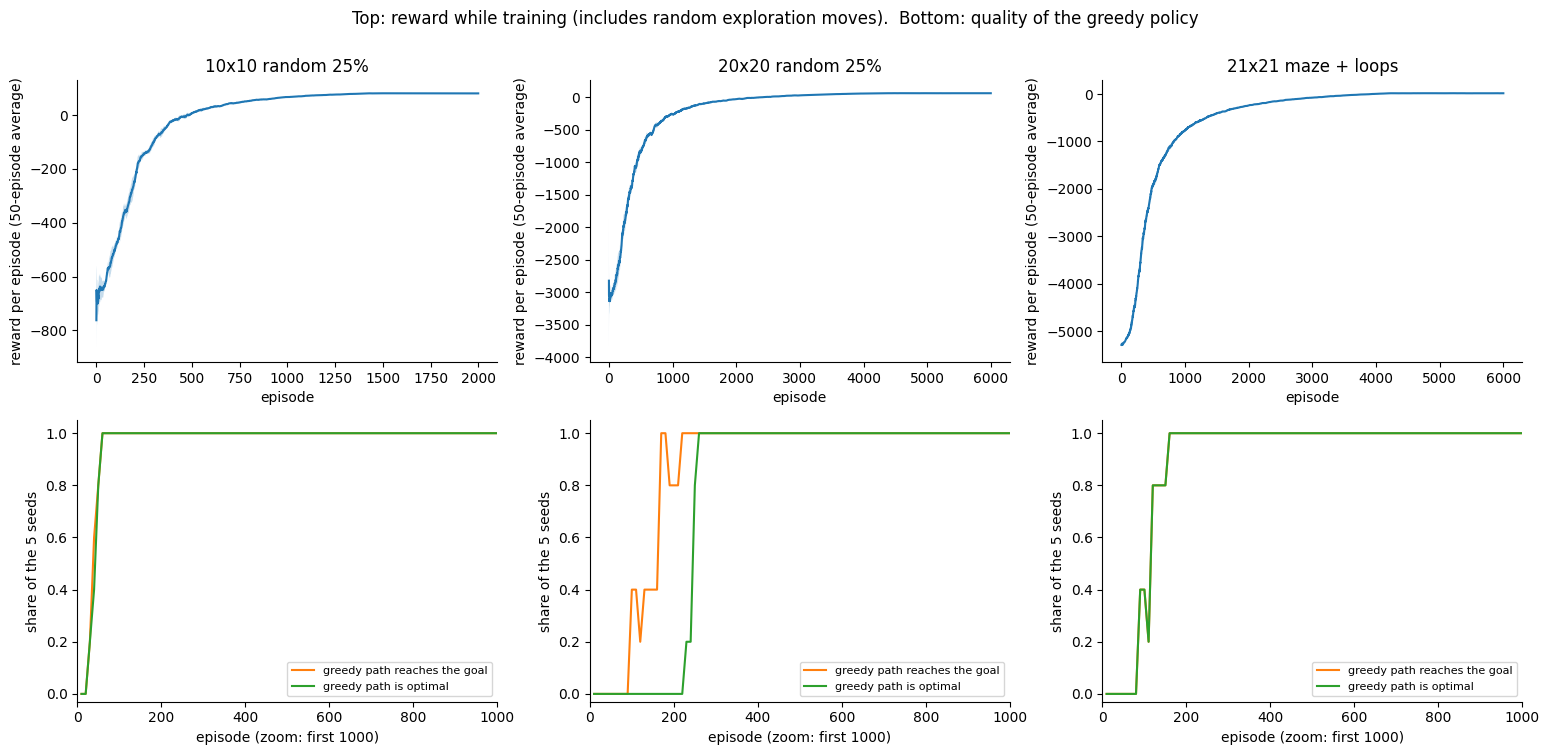

In [15]:
fig, ax = plt.subplots(2, len(Q_CASES), figsize=(5.2 * len(Q_CASES), 7.5))
for j, (name, (grid, start, goal), episodes) in enumerate(Q_CASES):
    opt = int(dist_map(grid, goal)[start])
    runs = q_runs[name]
    R = np.array([pd.Series(r["rewards"]).rolling(50, min_periods=1).mean().values for r in runs])
    ax[0, j].plot(R.mean(0), color="tab:blue")
    ax[0, j].fill_between(range(episodes), R.mean(0) - R.std(0), R.mean(0) + R.std(0), alpha=0.25)
    ax[0, j].set(title=name, xlabel="episode", ylabel="reward per episode (50-episode average)")

    ep = [c[0] for c in runs[0]["checks"]]
    found = np.array([[c[1] is not None for c in r["checks"]] for r in runs], dtype=float)
    best = np.array([[c[1] == opt for c in r["checks"]] for r in runs], dtype=float)
    ax[1, j].plot(ep, found.mean(0), label="greedy path reaches the goal", color="tab:orange")
    ax[1, j].plot(ep, best.mean(0), label="greedy path is optimal", color="tab:green")
    ax[1, j].set(xlim=(0, 1000), ylim=(-0.03, 1.05), xlabel="episode (zoom: first 1000)",
                 ylabel=f"share of the {Q_SEEDS} seeds")
    ax[1, j].legend(loc="lower right", fontsize=8)
plt.suptitle("Top: reward while training (includes random exploration moves).  Bottom: quality of the greedy policy", y=1.0)
plt.tight_layout()
plt.savefig(f"{OUT}/q_learning_curves.png", dpi=120, bbox_inches="tight")
plt.show()

**Why do the two rows look so different?** The greedy policy (bottom) is already optimal after only a few hundred episodes. The reward curve (top) keeps rising much longer because during training the agent still takes **random exploration moves** (`epsilon` decays slowly), and those moves hit walls and cost reward. Learning the best path and *behaving* greedily are two different things.

### 7.2 See what the agent learned

- **Left:** the value of every cell `max Q(s,a)`. Brighter = closer to the goal in the agent's belief.
- **Right:** the policy as arrows (the best action in each cell the agent has learned about). The red line is the path from the start.

Cells the agent never visited have no arrows (it learned nothing about them).

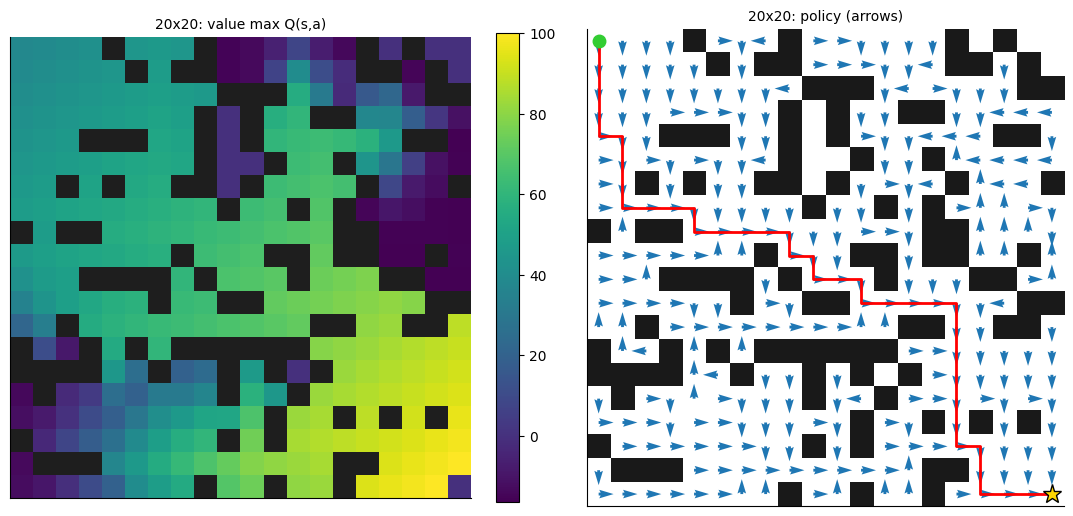

In [16]:
def plot_policy(res, ax_val, ax_pol, title):
    grid, start, goal = res["grid"], res["start"], res["goal"]
    n, m = grid.shape
    Q = np.array(res["Q"]).reshape(n, m, 4)
    path = extract_path(res["Q"], res["nxt"], start, goal, m)

    hm = np.where(grid == 1, np.nan, Q.max(axis=2))
    cmap_v = plt.cm.viridis.copy(); cmap_v.set_bad("0.12")      # walls = dark
    im = ax_val.imshow(hm, cmap=cmap_v)
    ax_val.set_title(f"{title}: value max Q(s,a)", fontsize=10)
    plt.colorbar(im, ax=ax_val, fraction=0.046)

    ax_pol.imshow(np.where(grid == 1, 0.1, 1.0), cmap="gray", vmin=0, vmax=1)
    rr, cc = np.nonzero(grid == 0)
    learned = (Q[rr, cc] != 0).any(axis=1)
    rr, cc = rr[learned], cc[learned]
    act = Q[rr, cc].argmax(axis=1)
    ax_pol.quiver(cc, rr, [MOVES[k][1] for k in act], [MOVES[k][0] for k in act],
                  color="tab:blue", angles="xy", scale_units="xy", scale=1.6, width=0.006)
    if path:
        ax_pol.plot([c for _, c in path], [r for r, _ in path], color="red", lw=2)
    ax_pol.plot(start[1], start[0], "o", color="limegreen", ms=9)
    ax_pol.plot(goal[1], goal[0], "*", color="gold", ms=14, mec="k")
    ax_pol.set_title(f"{title}: policy (arrows)", fontsize=10)
    for a_ in (ax_val, ax_pol):
        a_.set_xticks([]); a_.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
plot_policy(q_runs["20x20 random 25%"][0], axes[0], axes[1], "20x20")
plt.tight_layout()
plt.savefig(f"{OUT}/q_policy_20x20.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
# GIF: the greedy path improving while the agent trains
grid, start, goal = Q_CASES[1][1]
snap_eps = [50, 100, 200, 400, 800, 1600, 3200, 6000]
frames = []
for e in snap_eps:
    r = train_q(grid, start, goal, episodes=e, seed=SEED, decay_frac=0.7 * 6000 / e)  # same epsilon schedule as the full run
    frames.append((e, extract_path(r["Q"], r["nxt"], start, goal, grid.shape[1])))

fig, ax = plt.subplots(figsize=(5, 5.2))
def update(i):
    ax.clear()
    e, p = frames[i]
    label = "no valid path yet" if p is None else f"path = {len(p) - 1} steps"
    draw(grid, start, goal, p, None, f"After {e} episodes: {label}", ax)
FuncAnimation(fig, update, frames=len(frames)).save(f"{OUT}/anim_q_learning.gif", writer=PillowWriter(fps=1))
plt.close(fig)
print("Saved anim_q_learning.gif")

Saved anim_q_learning.gif


### 7.3 How do the settings change learning?

Two experiments on the 10×10 maze (10 seeds each, 1500 episodes):

1. **Learning rate × discount** (value = share of seeds that found the optimal path).
2. **Reward design.** RL agents do what the *reward* says, not what you *meant*. Watch what happens when the rewards are poor.

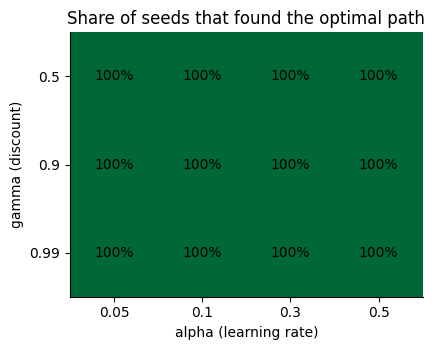

,reward_design,found_path,optimal_path,mean_steps,true_optimal
0,"default (-1, -5, +100)",10/10,10/10,18.0,18
1,"no wall penalty (-1, 0, +100)",10/10,10/10,18.0,18
2,"no step cost (0, -5, +100)",10/10,10/10,18.0,18
3,"only goal reward (0, 0, +100)",10/10,10/10,18.0,18
4,"step REWARD (+1, -5, +100)",3/10,3/10,18.0,18


In [18]:
grid, start, goal = make_random_maze(10, 0.25, seed=SEED)
opt = int(dist_map(grid, goal)[start])
alphas, gammas, SW = [0.05, 0.1, 0.3, 0.5], [0.5, 0.9, 0.99], 10

def optimal_share(**kw):
    ok = 0
    for sd in range(SW):
        r = train_q(grid, start, goal, episodes=1500, seed=SEED + sd, **kw)
        p = extract_path(r["Q"], r["nxt"], start, goal, grid.shape[1])
        ok += (p is not None and len(p) - 1 == opt)
    return ok / SW

tab = np.array([[optimal_share(alpha=a, gamma=g) for a in alphas] for g in gammas])

fig, ax = plt.subplots(figsize=(5.5, 3.6))
im = ax.imshow(tab, vmin=0, vmax=1, cmap="RdYlGn")
ax.set_xticks(range(len(alphas))); ax.set_xticklabels(alphas); ax.set_xlabel("alpha (learning rate)")
ax.set_yticks(range(len(gammas))); ax.set_yticklabels(gammas); ax.set_ylabel("gamma (discount)")
for i in range(len(gammas)):
    for j in range(len(alphas)):
        ax.text(j, i, f"{tab[i, j]:.0%}", ha="center", va="center")
ax.set_title("Share of seeds that found the optimal path")
plt.tight_layout(); plt.savefig(f"{OUT}/q_hyperparameters.png", dpi=120); plt.show()

VARIANTS = {
    "default (-1, -5, +100)":      (-1, -5, 100),
    "no wall penalty (-1, 0, +100)": (-1, 0, 100),
    "no step cost (0, -5, +100)":  (0, -5, 100),
    "only goal reward (0, 0, +100)": (0, 0, 100),
    "step REWARD (+1, -5, +100)":  (1, -5, 100),
}
rows_r = []
for name, rw in VARIANTS.items():
    found = optimal = 0
    steps_list = []
    for sd in range(SW):
        r = train_q(grid, start, goal, episodes=1500, seed=SEED + sd, rewards=rw)
        p = extract_path(r["Q"], r["nxt"], start, goal, grid.shape[1])
        found += p is not None
        optimal += (p is not None and len(p) - 1 == opt)
        if p is not None: steps_list.append(len(p) - 1)
    rows_r.append(dict(reward_design=name, found_path=f"{found}/{SW}", optimal_path=f"{optimal}/{SW}",
                       mean_steps=np.mean(steps_list) if steps_list else None, true_optimal=opt))
reward_df = pd.DataFrame(rows_r)
display(reward_df)
reward_df.to_csv(f"{OUT}/q_reward_design.csv", index=False)

**What to notice in the reward table**

- With `gamma < 1`, rewards far in the future are worth less, so even with **no step cost** the agent still prefers short paths. The discount works like a hidden step cost.
- The `+1 per step` row is classic *reward hacking*. Walking forever is worth `1 / (1 - 0.99) = 100`, the same as reaching the goal, so wandering is as good as finishing. In this run only **3 of 10 seeds** found a path to the goal at all (the other 7 learned to wander). Every other reward design succeeded in 10/10 seeds, so on this small maze the wall penalty and step cost are not essential, but a wrongly signed step reward breaks learning.


### 7.4 One policy for every starting cell

A\* answers **one** question: "path from this start to this goal". For a new start it must search again.
A Q-table is different: it holds the best action for **every cell it has learned about**, so it can start from anywhere with no new search.

Here a policy trained from the fixed start is compared with one trained from **random start cells**, for several training budgets (5 seeds each). Both are tested from **every** reachable cell of the 20×20 maze.
Early random exploration already teaches the fixed-start agent about many cells, but random starts cover the maze evenly.

reaches_goal  optimal_path  state_visits
episodes training                                               
300      fixed start           0.417         0.388      111049.0
         random starts         0.391         0.376       97687.6
1000     fixed start           0.732         0.725      201276.2
         random starts         0.854         0.838      168498.6
3000     fixed start           0.885         0.849      492735.8
         random starts         1.000         0.986      344371.2
6000     fixed start           0.978         0.941      966291.2
         random starts         1.000         0.985      644369.6

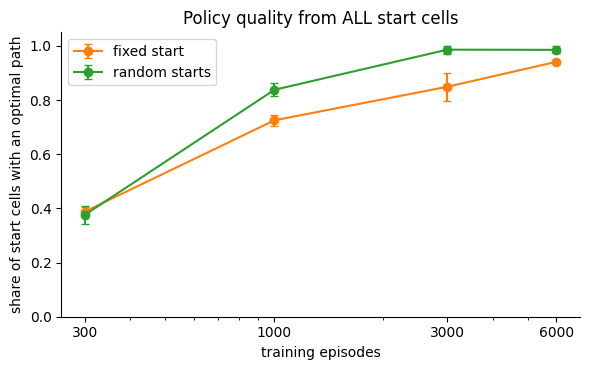

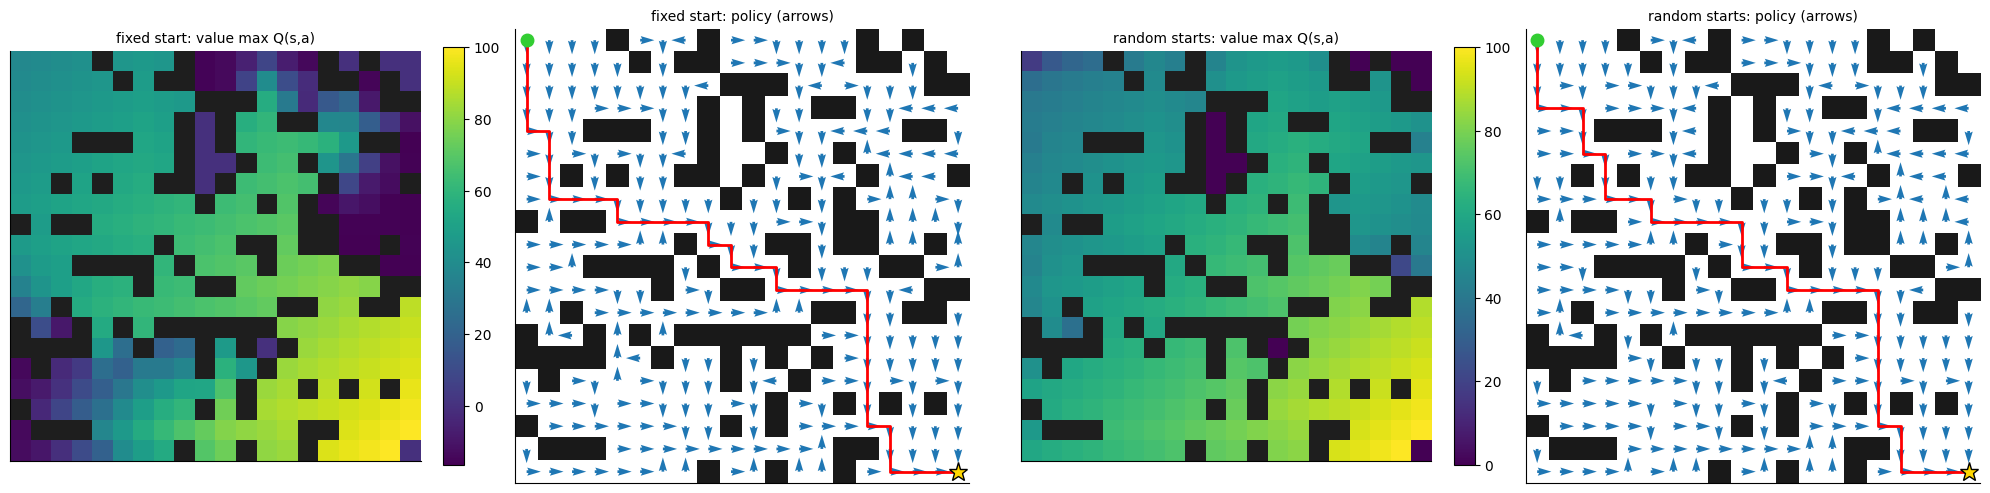

In [19]:
grid, start, goal = Q_CASES[1][1]
n_, m_ = grid.shape
dist = dist_map(grid, goal)
cells = [tuple(c) for c in np.argwhere(dist > 0)]

def eval_all_starts(res):
    ok = opt_ = 0
    for cell in cells:
        p = extract_path(res["Q"], res["nxt"], cell, goal, m_)
        if p is not None:
            ok += 1
            opt_ += (len(p) - 1 == dist[cell])
    return ok / len(cells), opt_ / len(cells)

BUDGETS = [300, 1000, 3000, 6000]
GEN_SEEDS = 5
gen_rows, final = [], {}
for eps in BUDGETS:
    for name, rs in [("fixed start", False), ("random starts", True)]:
        for sd in range(GEN_SEEDS):
            res = train_q(grid, start, goal, episodes=eps, seed=SEED + sd, random_start=rs)
            s_ok, s_opt = eval_all_starts(res)
            gen_rows.append(dict(episodes=eps, training=name, seed=sd, reaches_goal=s_ok,
                                 optimal_path=s_opt, state_visits=res["visits"]))
            if eps == BUDGETS[-1] and sd == 0:
                final[name] = res
gen_df = pd.DataFrame(gen_rows)
gen_df.to_csv(f"{OUT}/q_generalization.csv", index=False)
gen_mean = gen_df.groupby(["episodes", "training"])[["reaches_goal", "optimal_path", "state_visits"]].mean().round(3)
display(gen_mean)

fig, ax = plt.subplots(figsize=(6, 3.8))
for name, col in [("fixed start", "tab:orange"), ("random starts", "tab:green")]:
    d = gen_df[gen_df.training == name].groupby("episodes")["optimal_path"].agg(["mean", "std"])
    ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=name, color=col)
ax.set(xscale="log", xlabel="training episodes", ylabel="share of start cells with an optimal path",
       title="Policy quality from ALL start cells", ylim=(0, 1.05))
ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS); ax.xaxis.set_minor_formatter(NullFormatter()); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/q_generalization.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
plot_policy(final["fixed start"], axes[0], axes[1], "fixed start")
plot_policy(final["random starts"], axes[2], axes[3], "random starts")
plt.tight_layout(); plt.savefig(f"{OUT}/q_random_start_policy.png", dpi=110, bbox_inches="tight"); plt.show()

## 8. Final summary (generated from the numbers of this run)

The text below is built automatically from the results, so it always matches your data. It is also saved as `report.md`.

In [20]:
def safe(x, fmt="{:.1f}"):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else fmt.format(x)

n_mazes = len(bench) // len(ALGOS)
r_rand = red.loc[("random", "A* (Manhattan)"), "mean"]
r_maze = red.loc[("perfect maze", "A* (Manhattan)"), "mean"]
r_trap = red.loc[("trap", "A* (Manhattan)"), "mean"]
r_euc = red.loc[("random", "A* (Euclidean)"), "mean"]
r_w = red.loc[("random", "Weighted A* (w=2)"), "mean"]
w_opt = bench[(bench.algo == "Weighted A* (w=2)")]["optimality"].mean()
big = bench[(bench.kind == "random") & (bench.n == 100)].groupby("algo")["runtime_ms"].mean()
bad_opt = bench[bench.algo.isin(["Dijkstra", "A* (Manhattan)", "A* (Euclidean)"])]["optimality"].max()

qs = q_summary
lines = [
    "# Results report", "",
    f"- Planning benchmark: **{len(bench)} runs** on **{n_mazes} mazes** ({len(ALGOS)} algorithms). "
    f"Correctness tests: **{n_checks} checks passed**.",
    f"- Dijkstra, A* (Manhattan) and A* (Euclidean) always found the optimal path (largest optimality ratio: {bad_opt:.3f}).", "",
    "## Planning (Dijkstra / A*)",
    f"- On **random obstacle mazes** A* (Manhattan) expanded **{r_rand:.0f}% fewer nodes** than Dijkstra; "
    f"on **perfect mazes with loops** {r_maze:.0f}% (corridors leave little room for a heuristic); on the **trap** maze {r_trap:.0f}% "
    "(the heuristic points into the wall, so A* first fills the pocket in front of it).",
    f"- A* (Euclidean) is a weaker heuristic: {r_euc:.0f}% fewer nodes on random mazes (Manhattan is the exact lower bound on a 4-direction grid).",
    f"- Weighted A* (w=2): {r_w:.0f}% fewer nodes on random mazes, but paths were on average {100 * (w_opt - 1):.1f}% longer than optimal.",
    f"- Runtime on 100x100 random mazes: Dijkstra {big['Dijkstra']:.1f} ms, A* (Manhattan) {big['A* (Manhattan)']:.1f} ms "
    f"({big['Dijkstra'] / big['A* (Manhattan)']:.1f}x faster).", "",
    "## Q-learning",
]
ratios = []
for name in qs.index:
    row = qs.loc[name]
    ratio = row["visits_to_converge"] / row["astar_expanded"]
    ratios.append(ratio)
    lines.append(f"- **{name}**: optimal path in {row['optimal']:.0%} of seeds. The greedy path was always optimal after about "
                 f"{safe(row['converged_at_median'], '{:.0f}')} episodes ({safe(row['visits_to_converge'], '{:,.0f}')} cell visits). "
                 f"A* needed {row['astar_expanded']:.0f} expanded nodes ({row['astar_ms']:.2f} ms). "
                 f"The full training run ({row['episodes']:.0f} episodes) took {row['train_ms']:.0f} ms.")
ratios = [x for x in ratios if not np.isnan(x)]
if ratios:
    lines.append(f"- To converge, Q-learning visited roughly **{min(ratios):,.0f}x to {max(ratios):,.0f}x more cells** than A* expanded.")

rd = reward_df.set_index("reward_design")
gm = gen_mean.reset_index()
def gen_val(eps, train, col):
    return gm[(gm.episodes == eps) & (gm.training == train)][col].iloc[0]
mid = BUDGETS[2]
lines += [
    f"- **Reward design:** with the default rewards {rd.loc['default (-1, -5, +100)', 'optimal_path']} seeds found the optimal path; "
    f"with no step cost {rd.loc['no step cost (0, -5, +100)', 'optimal_path']} (the discount gamma < 1 acts as a hidden step cost); "
    f"with a +1 reward per step only {rd.loc['step REWARD (+1, -5, +100)', 'found_path']} found a path to the goal at all.",
    f"- **One policy for every start cell** (20x20, {mid} episodes): trained from a fixed start, the policy is optimal from "
    f"{gen_val(mid, 'fixed start', 'optimal_path'):.0%} of cells; trained from random starts: {gen_val(mid, 'random starts', 'optimal_path'):.0%}. "
    f"With {BUDGETS[-1]} episodes: {gen_val(BUDGETS[-1], 'fixed start', 'optimal_path'):.0%} vs {gen_val(BUDGETS[-1], 'random starts', 'optimal_path'):.0%}.", "",
    "## Limitations",
    "- 4-direction moves and unit step cost only (no diagonals, no terrain weights).",
    "- Runtimes are pure-Python wall-clock times (median of 5 runs) and include interpreter overhead; compare them relatively, not absolutely.",
    "- Q-learning results use 5 seeds per maze, the reward and hyper-parameter studies use 10 seeds on one 10x10 maze, so treat those as small-sample evidence.",
    "- Trap-maze statistics come from a clean trap plus 10 noisy variants per size.", "",
    "## Conclusion",
    "- If the full map is known, use **A\\*** (optimal and cheapest). Dijkstra is the safe choice when no good heuristic exists.",
    "- Heuristics trade speed for optimality: Manhattan is both fast and optimal here; Weighted A* is faster but its paths may be longer.",
    "- Q-learning finds the optimal path too, but it needs far more computation for a single path. Its strength is that it needs **no map**, "
    "learns from experience, and one trained policy can start from many cells. That is when RL is worth its cost.",
]
report = "\n".join(lines)
with open(f"{OUT}/report.md", "w") as f:
    f.write(report)
display(Markdown(report))

# Results report

- Planning benchmark: **852 runs** on **213 mazes** (4 algorithms). Correctness tests: **840 checks passed**.
- Dijkstra, A* (Manhattan) and A* (Euclidean) always found the optimal path (largest optimality ratio: 1.000).

## Planning (Dijkstra / A*)
- On **random obstacle mazes** A* (Manhattan) expanded **79% fewer nodes** than Dijkstra; on **perfect mazes with loops** 16% (corridors leave little room for a heuristic); on the **trap** maze 45% (the heuristic points into the wall, so A* first fills the pocket in front of it).
- A* (Euclidean) is a weaker heuristic: 19% fewer nodes on random mazes (Manhattan is the exact lower bound on a 4-direction grid).
- Weighted A* (w=2): 88% fewer nodes on random mazes, but paths were on average 5.0% longer than optimal.
- Runtime on 100x100 random mazes: Dijkstra 29.2 ms, A* (Manhattan) 5.2 ms (5.6x faster).

## Q-learning
- **10x10 random 25%**: optimal path in 100% of seeds. The greedy path was always optimal after about 50 episodes (17,121 cell visits). A* needed 20 expanded nodes (0.08 ms). The full training run (2000 episodes) took 121 ms.
- **20x20 random 25%**: optimal path in 100% of seeds. The greedy path was always optimal after about 250 episodes (310,338 cell visits). A* needed 45 expanded nodes (0.17 ms). The full training run (6000 episodes) took 929 ms.
- **21x21 maze + loops**: optimal path in 100% of seeds. The greedy path was always optimal after about 120 episodes (208,840 cell visits). A* needed 86 expanded nodes (0.27 ms). The full training run (6000 episodes) took 1403 ms.
- To converge, Q-learning visited roughly **856x to 6,896x more cells** than A* expanded.
- **Reward design:** with the default rewards 10/10 seeds found the optimal path; with no step cost 10/10 (the discount gamma < 1 acts as a hidden step cost); with a +1 reward per step only 3/10 found a path to the goal at all.
- **One policy for every start cell** (20x20, 3000 episodes): trained from a fixed start, the policy is optimal from 85% of cells; trained from random starts: 99%. With 6000 episodes: 94% vs 98%.

## Limitations
- 4-direction moves and unit step cost only (no diagonals, no terrain weights).
- Runtimes are pure-Python wall-clock times (median of 5 runs) and include interpreter overhead; compare them relatively, not absolutely.
- Q-learning results use 5 seeds per maze, the reward and hyper-parameter studies use 10 seeds on one 10x10 maze, so treat those as small-sample evidence.
- Trap-maze statistics come from a clean trap plus 10 noisy variants per size.

## Conclusion
- If the full map is known, use **A\*** (optimal and cheapest). Dijkstra is the safe choice when no good heuristic exists.
- Heuristics trade speed for optimality: Manhattan is both fast and optimal here; Weighted A* is faster but its paths may be longer.
- Q-learning finds the optimal path too, but it needs far more computation for a single path. Its strength is that it needs **no map**, learns from experience, and one trained policy can start from many cells. That is when RL is worth its cost.

In [21]:
archive = shutil.make_archive(os.path.join(os.path.dirname(OUT.rstrip("/")) or ".", "results_bundle"), "zip", OUT)
print("ZIP with all results:", archive)
for fn in sorted(os.listdir(OUT)):
    print(f"{os.path.getsize(os.path.join(OUT, fn)) / 1024:8.0f} KB  {fn}")

ZIP with all results: /kaggle/working/results_bundle.zip
      29 KB  anim_q_learning.gif
     372 KB  anim_random.gif
     279 KB  anim_trap.gif
      76 KB  metrics_planners.csv
       2 KB  metrics_qlearning.csv
     140 KB  planner_comparison.png
       2 KB  q_generalization.csv
      40 KB  q_generalization.png
      22 KB  q_hyperparameters.png
     125 KB  q_learning_curves.png
     103 KB  q_policy_20x20.png
     167 KB  q_random_start_policy.png
       0 KB  q_reward_design.csv
       3 KB  report.md
      39 KB  search_Maze_31x31_with_5%_loops.png
      43 KB  search_Random_30x30.png
      36 KB  search_Trap_30x30.png
      59 KB  search_logs.json
       1 KB  summary_planners.csv


## 9. Limitations

- Movement is 4-directional with unit step cost (no diagonals, no terrain weights).
- Runtimes are pure-Python wall-clock times (median of 5 runs). They include interpreter overhead, so compare them *relatively*.
- Q-learning is evaluated with 5 seeds per maze; the reward / hyper-parameter studies use 10 seeds on one 10x10 maze. Treat them as small-sample evidence.
- Random mazes are filtered to be solvable, which slightly biases them toward easier layouts at high wall density.


## 9. Ideas to extend this project

1. 8-direction movement (diagonals) with the octile heuristic.
2. Different terrain costs (mud, road) so that Dijkstra and A\* must handle weights.
3. SARSA and Double Q-learning compared with Q-learning.
4. Deep Q-Network (DQN) for larger or changing mazes.
5. Bidirectional search and Jump Point Search for faster planning.